# Tabular — Active Learning (uncertainty sampling)
**Kapan dipakai:** label mahal, kita hanya sanggup melabeli sedikit baris. Daripada memilih
baris secara acak, minta label untuk baris yang **paling diragukan model**.

**Putaran:** latih → pilih 20 baris paling ragu → "oracle" memberi label → ulangi.
Di notebook ini oracle = label asli yang disembunyikan (simulasi). Saat lomba oracle = kita
sendiri, lihat `anotasi_teks` atau `anotasi_deteksi`.

**Hasil:** kurva F1 vs jumlah label, dibanding memilih baris secara acak. Pada data yang
sangat timpang keuntungannya bisa hilang, jadi selalu bandingkan.

**Data demo:** digits (1.797 gambar angka 8x8 sebagai 64 kolom piksel, 10 kelas).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/unsupervised"   # GANTI saat lomba
DATA_CSV = f"{DATA_FOLDER}/digits.csv"

TARGET = "digit"
N_START = 20            # jumlah label di awal (dipilih acak)
N_PER_ROUND = 20        # jumlah baris yang dilabeli tiap putaran
N_ROUNDS = 15           # jumlah putaran
N_REPEATS = 3           # ulangi dengan seed berbeda agar kurva stabil
SEED = 42

## Baca data

In [3]:
data = pd.read_csv(DATA_CSV)
print(data.shape)
print(data[TARGET].value_counts())

(1797, 65)
digit
3    183
1    182
5    182
4    181
6    181
9    180
7    179
0    178
2    177
8    174
Name: count, dtype: int64


## Split
- `pool`: label disembunyikan, dibuka satu per satu oleh oracle.
- `evaluation`: untuk mengukur F1 tiap putaran.

In [4]:
FEATURES = data.columns.drop(TARGET)
pool, evaluation = train_test_split(data, test_size=0.25, stratify=data[TARGET],
                                    random_state=SEED)
X_pool = pool[FEATURES].values
y_pool = pool[TARGET].values
X_eval = evaluation[FEATURES].values
y_eval = evaluation[TARGET].values
print("pool:", len(pool), "| evaluasi:", len(evaluation))

pool: 1347 | evaluasi: 450


## Ukuran keraguan
Makin besar = makin ragu. Pilih SATU blok `return`: hapus `#` di blok yang ingin dipakai.
- least confidence: 1 − probabilitas kelas teratas.
- margin: 1 − selisih dua kelas teratas.
- entropy: makin rata probabilitasnya, makin ragu.

In [5]:
def doubt_score(proba):
    return 1 - proba.max(axis=1)
    # proba = np.sort(proba, axis=1)
    # return 1 - (proba[:, -1] - proba[:, -2])
    # return -(proba * np.log(proba + 1e-12)).sum(axis=1)


# coba pada dua contoh: yakin (0.9) dan ragu (0.4 vs 0.35)
example_proba = np.array([[0.9, 0.05, 0.05], [0.4, 0.35, 0.25]])
print("skor ragu contoh:", doubt_score(example_proba))

skor ragu contoh: [0.1 0.6]


## Loop active learning dan pembanding acak
`run_rounds(use_doubt=True)` memilih baris paling ragu; `use_doubt=False` memilih acak.

In [6]:
def run_rounds(use_doubt, seed):
    random_generator = np.random.default_rng(seed)
    labeled = list(random_generator.choice(len(X_pool), N_START, replace=False))
    curve = []
    for round_number in range(N_ROUNDS + 1):
        model = RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=4)
        model.fit(X_pool[labeled], y_pool[labeled])
        curve.append(f1_score(y_eval, model.predict(X_eval), average="macro"))
        remaining = np.setdiff1d(np.arange(len(X_pool)), labeled)
        if use_doubt:
            scores = doubt_score(model.predict_proba(X_pool[remaining]))
            order = np.argsort(-scores)
            picked = remaining[order[:N_PER_ROUND]]
        else:
            picked = random_generator.choice(remaining, N_PER_ROUND, replace=False)
        labeled = labeled + list(picked)    # oracle: label asli y_pool dibuka untuk baris ini
    return curve


doubt_curves = []
random_curves = []
for repeat in range(N_REPEATS):
    doubt_curves.append(run_rounds(True, SEED + repeat))
    random_curves.append(run_rounds(False, SEED + repeat))
doubt_curves = np.array(doubt_curves)
random_curves = np.array(random_curves)

## Kurva F1 vs jumlah label
Disimpan juga sebagai `kurva.csv` dan `kurva.png` untuk presentasi.

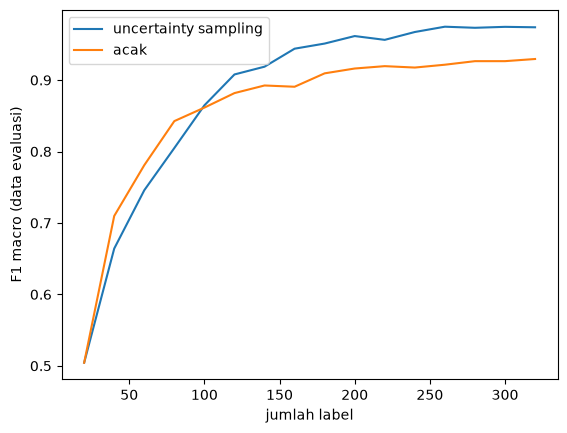

,jumlah_label,f1_ragu,f1_acak
0,20,0.504373,0.504373
4,100,0.864621,0.861450
8,180,0.951092,0.909402
12,260,0.974698,0.921484


In [7]:
label_counts = N_START + N_PER_ROUND * np.arange(N_ROUNDS + 1)
result = pd.DataFrame()
result["jumlah_label"] = label_counts
result["f1_ragu"] = doubt_curves.mean(axis=0)
result["f1_acak"] = random_curves.mean(axis=0)
result.to_csv("kurva.csv", index=False)

plt.plot(label_counts, result["f1_ragu"], label="uncertainty sampling")
plt.plot(label_counts, result["f1_acak"], label="acak")
plt.xlabel("jumlah label")
plt.ylabel("F1 macro (data evaluasi)")
plt.legend()
plt.savefig("kurva.png", dpi=100)
plt.show()
result.iloc[::4]

## Berapa label yang dihemat?
Cari jumlah label minimum agar pemilihan acak menyamai F1 akhir uncertainty sampling.

In [8]:
final_doubt = result["f1_ragu"].iloc[-1]
final_random = result["f1_acak"].iloc[-1]
enough = result[result["f1_acak"] >= final_doubt]["jumlah_label"]
print("F1 uncertainty sampling di", label_counts[-1], "label:", round(final_doubt, 4))
print("F1 acak di", label_counts[-1], "label:", round(final_random, 4))
if len(enough) > 0:
    print("label acak untuk menyamai:", enough.min())
else:
    print("label acak untuk menyamai: belum tercapai dalam batas putaran")

F1 uncertainty sampling di 320 label: 0.9739
F1 acak di 320 label: 0.9295
label acak untuk menyamai: belum tercapai dalam batas putaran
